In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import PolynomialFeatures , StandardScaler
from sklearn.pipeline import Pipeline

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score , mean_squared_error

In [3]:
housing = fetch_california_housing(as_frame=True)
x = housing.data
y = housing.target

In [4]:
x.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [5]:
y.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [6]:
x.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [7]:
x.shape

(20640, 8)

In [8]:
X = x[['MedInc']]
X.head()

,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


In [9]:
x_train ,  x_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state=42)

In [10]:
degrees = range(1,16)

In [11]:
train_errors=[]
test_errors=[]
train_r2=[]
test_r2=[]

models = {}

In [12]:
!pip install tqdm

In [13]:
from tqdm import tqdm
for degree in tqdm(degrees):
    model = Pipeline([
        ('poly',PolynomialFeatures(degree=degree)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ])
    model.fit(x_train , y_train)

    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)

    train_errors.append(mean_squared_error(y_train , y_train_pred))
    test_errors.append(mean_squared_error(y_test , y_test_pred))
    train_r2.append(r2_score(y_train , y_train_pred))
    test_r2.append(r2_score(y_test , y_test_pred))

    models[degree] = model

100%|██████████████████████████████████████████| 15/15 [00:00<00:00, 16.46it/s]


In [14]:
results = pd.DataFrame({
    'degree' : list(degrees),
    'training mse' : train_errors,
    'testing mse' : test_errors,
    'training r2' : train_r2,
    'testing r2' : test_r2
})

In [15]:
results

,degree,training mse,testing mse,training r2,testing r2
0,1,0.699145,0.709116,0.476993,0.458859
1,2,0.692989,0.703273,0.481598,0.463318
2,3,0.680680,0.698296,0.490806,0.467116
3,4,0.680542,0.698104,0.490909,0.467262
4,5,0.680368,0.698716,0.491039,0.466796
5,6,0.678843,0.695970,0.492180,0.468891
6,7,0.676124,0.693144,0.494214,0.471047
7,8,0.675940,0.692699,0.494352,0.471387
8,9,0.675928,0.692682,0.494360,0.471400
9,10,0.675926,0.692682,0.494362,0.471400


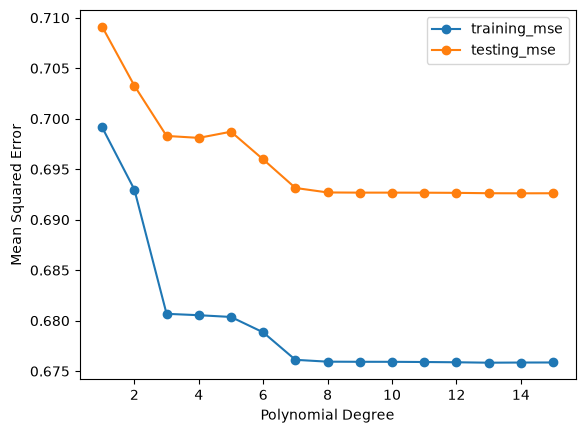

In [16]:
import matplotlib.pyplot as plt
plt.plot(degrees , train_errors , marker='o' , label='training_mse')
plt.plot(degrees , test_errors , marker='o' , label='testing_mse')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error')
plt.legend()

In [30]:
best_degree = list(degrees)[np.argmin(test_errors)]

In [31]:
best_degree

14

In [32]:
selected_degrees = [1,best_degree,15]
for degree in selected_degrees:
    index = degree-1
    print('Polynomial Degree ' ,degree)
    print(f'training MSE : {train_errors[index]}')
    print(f'testing MSE : {test_errors[index]}')
    print(f'trainng r2 : {train_r2[index]}')
    print(f'testing r2 : {test_r2[index]}')
    print()

Polynomial Degree  1
training MSE : 0.6991447170182824
testing MSE : 0.7091157771765549
trainng r2 : 0.47699273458205227
testing r2 : 0.45885918903846656

Polynomial Degree  14
training MSE : 0.6758541997781433
testing MSE : 0.6926149242611502
trainng r2 : 0.49441560775183724
testing r2 : 0.4714513287363763

Polynomial Degree  15
training MSE : 0.6758599967501556
testing MSE : 0.6926198279311137
trainng r2 : 0.49441127122692896
testing r2 : 0.4714475866451324



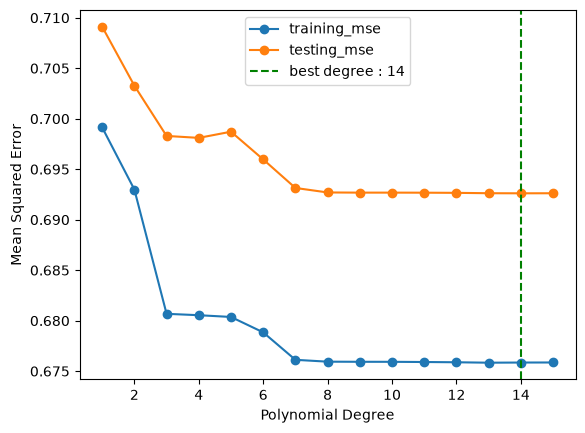

In [33]:
import matplotlib.pyplot as plt
plt.plot(degrees , train_errors , marker='o' , label='training_mse')
plt.plot(degrees , test_errors , marker='o' , label='testing_mse')
plt.axvline(best_degree , color='green' ,linestyle='--', label=f'best degree : {best_degree}')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error')
plt.legend()